# 🏥 TECH CHALLENGE — FASE 1 | FIAP PÓS-TECH
## Sistema Inteligente de Suporte ao Diagnóstico de Câncer de Mama
### 🎬 Notebook Executivo & Guia Interativo de Apresentação em Vídeo

---

### 📌 Como usar este Notebook na gravação do seu vídeo:
- Este arquivo contém **100% dos códigos do `tech-challenge.ipynb` original**, na mesma ordem exata.
- Cada seção possui:
  - 🎯 **O que estamos fazendo aqui:** Explicação simples e direta da etapa.
  - 💻 **Código em Ação:** Todas as células originais comentadas linha a linha.
  - 📊 **Resumo dos Resultados:** O que o gráfico ou número significa na medicina.
  - 🎙️ **O que falar no vídeo:** Frases prontas em primeira pessoa para guiar a sua fala.


# 1. Contexto e Objetivo do Projeto

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Apresentamos o desafio proposto por um grande hospital universitário: criar uma ferramenta de Machine Learning capaz de auxiliar a triagem rápida de laudos de câncer de mama utilizando o dataset *Breast Cancer Wisconsin*.



# 2. Carregamento e Preparação dos Dados

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Importamos as dependências necessárias e carregamos a base de dados clínicos, inspecionando suas dimensões e integridade.



In [1]:
# -------------------------------------------------------------
# ETAPA 1: INSTALAÇÃO DAS DEPENDÊNCIAS DO PROJETO
# Instalamos as bibliotecas necessárias para manipulação de dados,
# gráficos estatísticos e algoritmos de Machine Learning.
# -------------------------------------------------------------
%pip install -q numpy pandas matplotlib seaborn missingno scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
# -------------------------------------------------------------
# ETAPA 2: IMPORTAÇÃO DOS MÓDULOS E BIBLIOTECAS
# Carregamos ferramentas de análise (pandas, numpy), visualização 
# (matplotlib, seaborn, missingno) e modelagem (scikit-learn).
# -------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sb
import math

from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


### Inspeção inicial

Primeiro, vamos verificar a quantidade de registros e colunas, os tipos de dados e as principais estatísticas.



In [3]:
# Carregamento do dataset a partir do diretório local 'database'
dados = pd.read_csv("database/data.csv")


In [4]:
# Exibe a quantidade total de colunas presentes na base original
len(dados.columns)


33

In [5]:
# Exibe a dimensionalidade da base (número de linhas e número de colunas)
dados.shape


(569, 33)

In [6]:
# Estatísticas descritivas básicas: média, desvio padrão, mínimos, quartis e máximos
dados.describe()


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [7]:
# Exibe informações sobre tipos de dados e contagem preliminar de valores não nulos
dados.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Em `perimeter_mean`, a média é 91,97 e a mediana é 86,24. A média maior que a mediana é uma pista de que alguns valores altos puxam a média para cima. Vamos observar esse comportamento também no histograma.



### Limpeza dos Dados e Auditoria de Qualidade

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Removemos as colunas `id` e `Unnamed: 32`, checamos ausência de nulos e duplicatas.



In [8]:
# Visualização das 5 primeiras linhas para verificar os identificadores da base
dados.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


A coluna `Unnamed: 32` está completamente vazia, então vamos removê-la.

<Axes: >

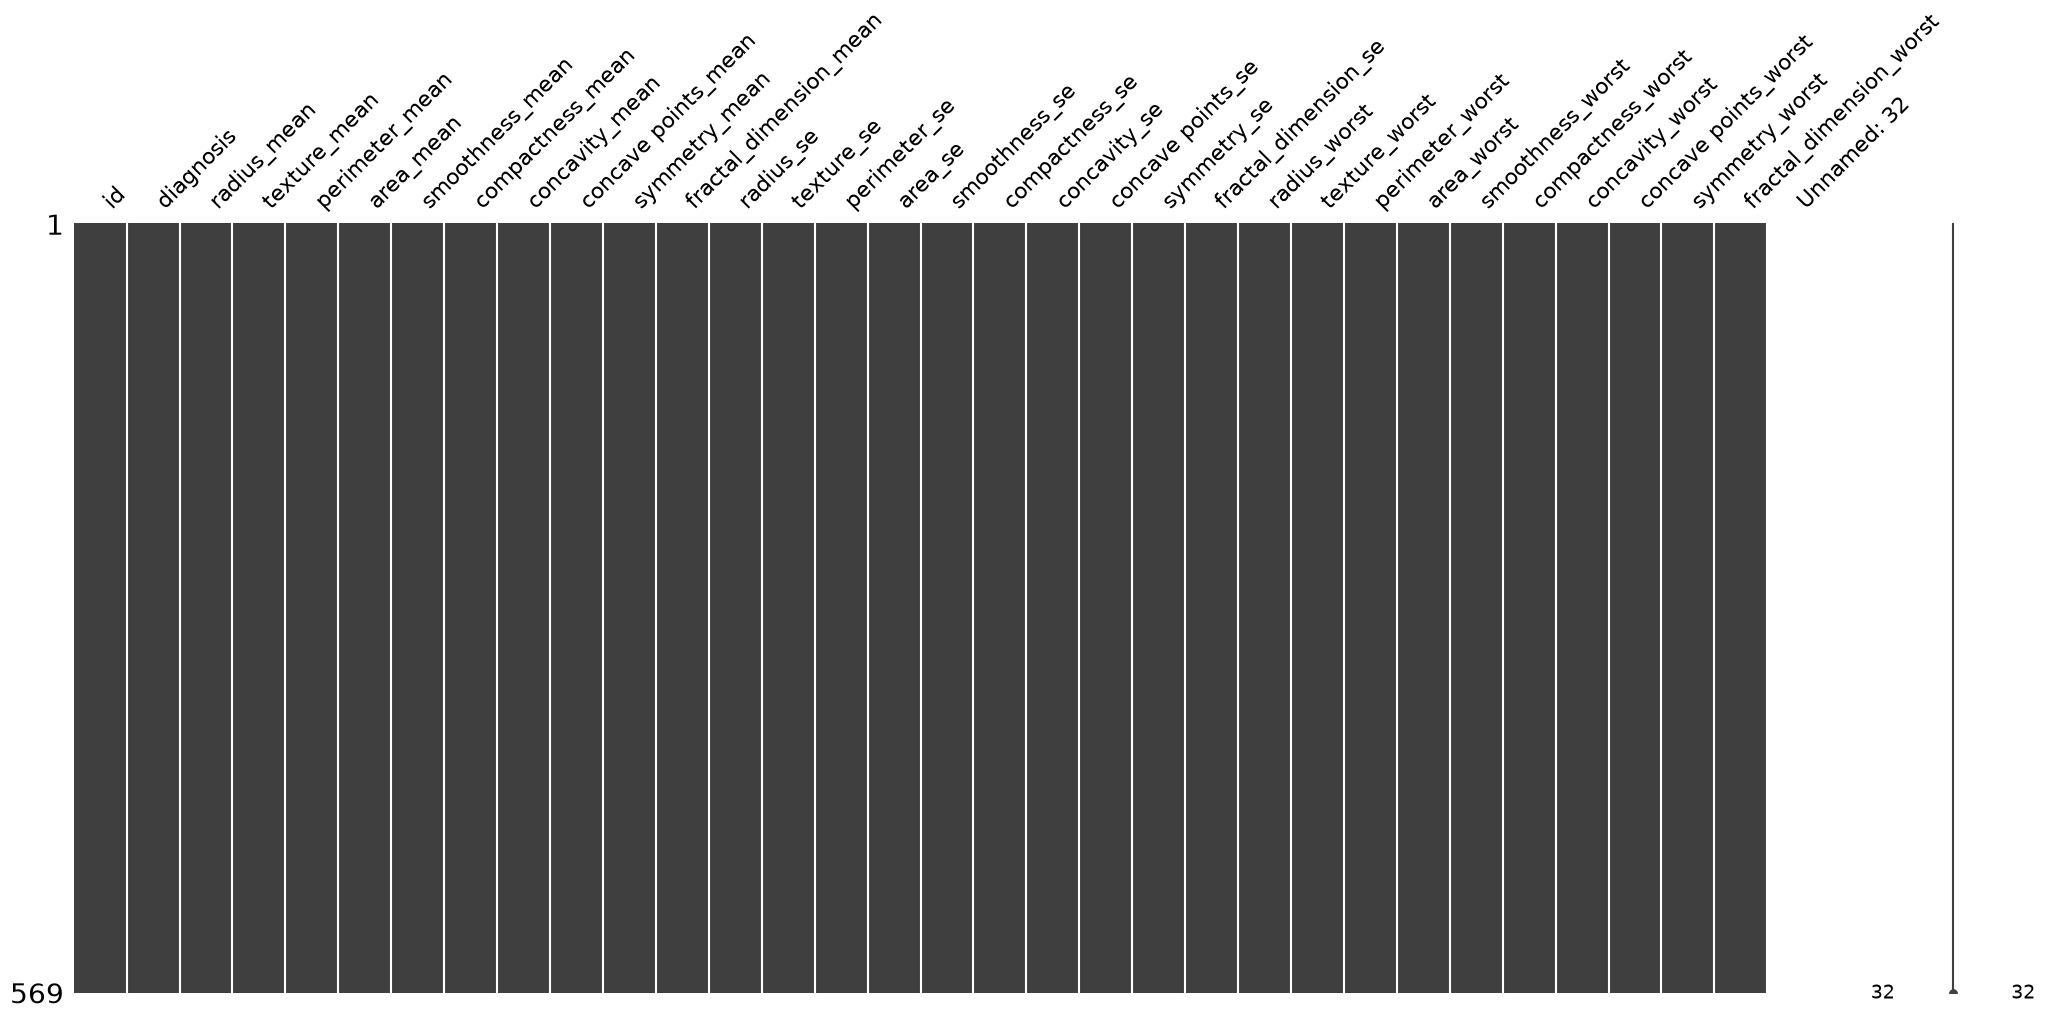

In [9]:
# Matriz de completude de dados (Missingno) - Linhas sólidas indicam dados presentes
msno.matrix(dados)


In [10]:
# Limpeza: Remoção de 'Unnamed: 32' (coluna 100% nula) e 'id' (sem relevância preditiva)
if "Unnamed: 32" in dados.columns:
    dados.drop("Unnamed: 32", axis=1, inplace=True)

if "id" in dados.columns:
    dados.drop("id", axis=1, inplace=True)

# Inspeção após a remoção das colunas desnecessárias
dados.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
# Auditoria de integridade: checagem de linhas duplicadas e valores ausentes restantes
print("Duplicados:", dados.duplicated().sum())
print("Valores ausentes:", dados.isna().sum().sum())


Duplicados: 0
Valores ausentes: 0


Após a limpeza, a base ficou com 569 registros, 30 características numéricas e a coluna de diagnóstico. Não encontramos valores ausentes nem registros duplicados, então não foi necessário preencher ou excluir registros.



### Transformação da Variável Diagnóstico (`LabelEncoder`)

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Convertemos Benigno para `0` e Maligno para `1`.



In [ ]:
# Verificação dos valores únicos presentes na variável alvo antes da codificação
# B = Benigno | M = Maligno
set(dados['diagnosis'])


In [ ]:
# Codificação da variável alvo (Label Encoding): Benigno -> 0 | Maligno -> 1
label = LabelEncoder()
dados['diagnosis'] = label.fit_transform(dados['diagnosis'])


In [ ]:
# Visualização do dataset pronto com a coluna 'diagnosis' codificada em 0 e 1
dados.head()


# 3. Análise Exploratória dos Dados (EDA)

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Analisamos as proporções de classe, a presença de outliers e as correlações com o diagnóstico.



### Distribuição dos diagnósticos

A base possui 357 registros benignos (62,7%) e 212 malignos (37,3%). Há mais casos benignos, então vamos considerar essa proporção ao dividir os dados.



In [ ]:
# Contagem visual da distribuição de diagnósticos na base
sb.countplot(data=dados, x="diagnosis")
plt.title("Distribuição dos diagnósticos (0 = Benigno, 1 = Maligno)")
plt.show()


### Distribuição dos valores e outliers

O boxplot ajuda a visualizar como os valores estão distribuídos. A caixa mostra os 50% centrais dos valores, a linha dentro dela indica a mediana e os pontos fora dos bigodes indicam possíveis outliers.



In [ ]:
# Boxplots das variáveis numéricas para identificação visual de valores extremos (outliers)
numericas = dados.drop(columns="diagnosis").select_dtypes(include="number")
dados_longos = numericas.melt(
    var_name="Coluna",
    value_name="Valor"
)

g = sb.catplot(
    data=dados_longos,
    x="Valor",
    col="Coluna",
    kind="box",
    col_wrap=3,
    sharex=False,
    sharey=False,
    height=3,
    aspect=1.2
)
g.set_titles("{col_name}")


Os boxplots mostram valores extremos em características como `perimeter_mean` e `area_mean`. Vamos mantê-los, pois um valor distante dos demais não significa necessariamente um erro e pode ajudar na classificação.



Os histogramas mostram quais faixas de valores são mais frequentes. Em `perimeter_mean`, por exemplo, há maior concentração aproximadamente entre 70 e 100 e poucos valores mais altos, formando uma cauda à direita.



In [ ]:
# Histogramas de frequência das variáveis para analisar assimetria e concentração
colunas = dados.drop(columns="diagnosis").select_dtypes(include="number").columns

por_linha = 3
linhas = math.ceil(len(colunas) / por_linha)

fig, axes = plt.subplots(
    linhas, por_linha,
    figsize=(15, 4 * linhas),
    squeeze=False
)

for ax, coluna in zip(axes.flat, colunas):
    sb.histplot(data=dados, x=coluna, ax=ax)
    ax.set_title(coluna)
    ax.set_ylabel("Frequência")

# Remove os eixos extras que sobraram na grade
for ax in list(axes.flat)[len(colunas):]:
    ax.remove()

plt.tight_layout()
plt.show()


Agora vamos comparar `perimeter_mean` entre benignos e malignos. Os casos malignos tendem a apresentar valores maiores, mas há uma faixa em que os dois grupos se misturam. Por isso, essa característica sozinha não separa todos os diagnósticos.

Como os grupos têm tamanhos diferentes, o histograma usa densidade para comparar onde os valores de cada grupo se concentram. Nesse formato, a área total das barras de cada grupo é igual a 1; a altura não é uma contagem de registros.



In [ ]:
# Comparação do perímetro médio ('perimeter_mean') entre casos benignos e malignos
visualizacao = dados.assign(
    diagnostico=dados["diagnosis"].map({0: "Benigno", 1: "Maligno"})
)
paleta_diagnostico = {"Benigno": "#2ca02c", "Maligno": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sb.histplot(
    data=visualizacao,
    x="perimeter_mean",
    hue="diagnostico",
    palette=paleta_diagnostico,
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0]
)
axes[0].set_title("Distribuição do perímetro por diagnóstico")
axes[0].set_ylabel("Densidade")

sb.boxplot(
    data=visualizacao,
    x="perimeter_mean",
    y="diagnostico",
    hue="diagnostico",
    palette=paleta_diagnostico,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Perímetro por diagnóstico")

plt.tight_layout()
plt.show()


As maiores correlações com o diagnóstico aparecem em `concave points_worst`, `perimeter_worst`, `concave points_mean` e `radius_worst`, próximas de 0,78. Como maligno foi representado por 1, a correlação positiva indica que valores maiores dessas características estão associados aos casos malignos nesta base.

Raio, perímetro e área também têm correlações altas entre si, mostrando que algumas colunas trazem informações parecidas. Essas relações ajudam a entender os dados, mas não significam que uma característica determine o diagnóstico.



In [ ]:
# Cálculo da matriz de correlação e filtro das 10 variáveis mais correlacionadas com o alvo
correlacoes = dados.corr(numeric_only=True)

mais_correlacionadas = (
    correlacoes["diagnosis"]
    .drop("diagnosis")
    .dropna()
    .abs()
    .nlargest(10)
    .index
)

# Monta o mapa de calor (Heatmap) com o diagnóstico e as variáveis mais fortes
colunas = ["diagnosis"] + mais_correlacionadas.tolist()
matriz_menor = correlacoes.loc[colunas, colunas]

fig, ax = plt.subplots(figsize=(12, 9))
sb.heatmap(
    matriz_menor,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    ax=ax
)
ax.set_title("Variáveis com maior correlação com o diagnóstico")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Para facilitar a leitura do `pairplot`, vamos usar as três características mais correlacionadas com o diagnóstico. As cores permitem comparar os grupos e observar onde eles se separam ou se misturam.



In [ ]:
# Pairplot com as três variáveis mais correlacionadas para visualizar separabilidade
variaveis_pairplot = [
    "concave points_worst",
    "perimeter_worst",
    "concave points_mean"
]

sb.pairplot(
    data=visualizacao,
    vars=variaveis_pairplot,
    hue="diagnostico",
    hue_order=["Benigno", "Maligno"],
    palette=paleta_diagnostico,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.6}
)
plt.show()


In [ ]:
# Stripplot: distribuição individual de 'concave points_worst' por diagnóstico
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

ax = sb.stripplot(
    data=visualizacao,
    x="concave points_worst",
    y="diagnostico",
    order=["Benigno", "Maligno"],
    hue="diagnostico",
    palette=paleta_diagnostico,
    jitter=0.25,
    alpha=0.6,
    size=4,
    legend=False
)
ax.set(
    xlabel="Média dos três maiores valores de pontos côncavos",
    ylabel="Diagnóstico",
    title="Distribuição dos pontos côncavos por diagnóstico"
)
plt.tight_layout()
plt.show()


In [ ]:
# Stripplot: distribuição individual de 'perimeter_worst' por diagnóstico
visualizacao = dados.assign(
    diagnostico=dados["diagnosis"].map({0: "Benigno", 1: "Maligno"})
)

sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

ax = sb.stripplot(
    data=visualizacao,
    x="perimeter_worst",
    y="diagnostico",
    order=["Benigno", "Maligno"],
    hue="diagnostico",
    palette=paleta_diagnostico,
    jitter=0.25,
    alpha=0.6,
    size=4,
    legend=False
)
ax.set(
    xlabel="Média dos três maiores perímetros",
    ylabel="Diagnóstico",
    title="Distribuição do perímetro por diagnóstico"
)
plt.tight_layout()
plt.show()


# 4. Preparação das Variáveis

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Separamos a matriz de atributos preditores `X` (as 30 características clínicas) do vetor alvo `y` (o diagnóstico).


In [ ]:
# Separação das matrizes preditoras (X) e do vetor da variável dependente (y)
x = dados.drop(columns="diagnosis")
y = dados["diagnosis"]


# 5. Divisão Rigorosa dos Dados e Demonstração do Stratify

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Demonstramos empiricamente porque a estratificação (`stratify`) é vital e separamos os dados em 3 conjuntos: Treino (60%), Validação (20%) e Teste Cego (20%).



In [ ]:
# Demonstração didática: partição SEM stratify (apenas para comparar proporções)
x_demo_treino, x_demo_teste, y_demo_treino, y_demo_teste = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)


Sem estratificação, a diferença na proporção de benignos entre treino e teste foi de aproximadamente 0,58 ponto percentual. As proporções já ficaram próximas nesse sorteio. Vamos comparar com o uso de `stratify`.



In [ ]:
# Gráfico comparativo das proporções de classes SEM estratificação
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

ordem = [0, 1]
cores = ["#2ca02c", "#d62728"]

y_demo_treino.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar", color=cores, ax=axes[0]
)
y_demo_teste.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar", color=cores, ax=axes[1]
)
axes[0].set_title("Treino sem stratify")
axes[1].set_title("Teste sem stratify")

for ax in axes:
    ax.set_xticklabels(["Benigno", "Maligno"], rotation=0)
    ax.set_xlabel("Diagnóstico")
    ax.set_ylim(0, 1)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{b.get_height():.1%}" for b in container], padding=3)

axes[0].set_ylabel("Proporção")
plt.tight_layout()
plt.show()


In [ ]:
# Percentuais exatos sem estratificação
print("Treino (%)")
print(y_demo_treino.value_counts(normalize=True).sort_index() * 100)
print("\nTeste (%)")
print(y_demo_teste.value_counts(normalize=True).sort_index() * 100)


In [ ]:
# Demonstração didática: partição COM stratify (preservando o equilíbrio de classes)
x_demo_treino, x_demo_teste, y_demo_treino, y_demo_teste = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


In [ ]:
# Gráfico comparativo das proporções de classes COM estratificação
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

ordem = [0, 1]
cores = ["#2ca02c", "#d62728"]

y_demo_treino.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar", color=cores, ax=axes[0]
)
y_demo_teste.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar", color=cores, ax=axes[1]
)
axes[0].set_title("Treino com stratify")
axes[1].set_title("Teste com stratify")

for ax in axes:
    ax.set_xticklabels(["Benigno", "Maligno"], rotation=0)
    ax.set_xlabel("Diagnóstico")
    ax.set_ylim(0, 1)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{b.get_height():.1%}" for b in container], padding=3)

axes[0].set_ylabel("Proporção")
plt.tight_layout()
plt.show()


In [ ]:
# Percentuais exatos com estratificação garantida
print("Treino (%)")
print(y_demo_treino.value_counts(normalize=True).sort_index() * 100)
print("\nTeste (%)")
print(y_demo_teste.value_counts(normalize=True).sort_index() * 100)


Com `stratify`, a diferença entre treino e teste caiu de 0,58 para 0,52 ponto percentual. A melhora foi pequena porque o sorteio anterior já tinha produzido proporções próximas. Como o teste tem 114 registros, um único registro representa cerca de 0,88 ponto percentual, o que impede um ajuste exato das proporções.



### Conjuntos de treino, validação e teste

As divisões anteriores serviram para demonstrar o efeito do `stratify`. Esta é a única divisão usada para treinar e avaliar os modelos:

- Treino: 341 registros, cerca de 60%, para ensinar os modelos.
- Validação: 114 registros, cerca de 20%, para comparar as versões.
- Teste: 114 registros, cerca de 20%, para a avaliação final.

O conjunto de teste permanece reservado até a avaliação final.



In [ ]:
# DIVISÃO DEFINITIVA DOS DADOS: 60% Treino, 20% Validação e 20% Teste
# 1º Passo: Separa 20% para Teste cego
x_desenvolvimento, x_test, y_desenvolvimento, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)

# 2º Passo: Do restante, separa 25% para validação (20% do total)
x_train, x_val, y_train, y_val = train_test_split(
    x_desenvolvimento, y_desenvolvimento,
    test_size=0.25, stratify=y_desenvolvimento, random_state=42
)

print("Formato Treino:   ", x_train.shape, f"({len(x_train)} amostras)")
print("Formato Validação:", x_val.shape, f"({len(x_val)} amostras)")
print("Formato Teste:    ", x_test.shape, f"({len(x_test)} amostras)")


# 6. Modelos de Classificação e Construção de Pipelines

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Encapsulamos a padronização (`StandardScaler`) e os modelos (Regressão Logística e KNN) dentro de Pipelines do Scikit-Learn.



## Pipeline de regressão logística

Escolhemos a regressão logística por ser um modelo de classificação adequado a problemas com duas classes, como benigno e maligno.

O pipeline reúne a padronização e o modelo. O `StandardScaler` coloca as características em escalas comparáveis, já que área, perímetro e outras medidas têm valores muito diferentes. Ele calcula a média e o desvio padrão apenas no treino e usa esses mesmos valores nos outros conjuntos.



In [ ]:
# Pipeline 1: Regressão Logística com StandardScaler integrado
modelo_regressao = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


## Pipeline do KNN

O KNN final usa `StandardScaler` e `KNeighborsClassifier` com `n_neighbors=5`.



In [ ]:
# Pipeline 2: K-Nearest Neighbors (KNN) com StandardScaler integrado
modelo_knn = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", KNeighborsClassifier(
        n_neighbors=5
    ))
])


# 7. Validação, Escolha do Hiperparâmetro K e Experimento de Features

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Testamos diferentes valores de K para o KNN na validação e comparamos o modelo de 30 características contra 10 características.



In [ ]:
# Loop de teste de hiperparâmetro K no conjunto de VALIDAÇÃO (K = 3, 5, 7, 9, 11)
for k in [3, 5, 7, 9, 11]:
    modelo_knn_k = Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=k))
    ])
    modelo_knn_k.fit(x_train, y_train)
    y_val_pred = modelo_knn_k.predict(x_val)
    print(
        f"K={k:2d} | "
        f"Accuracy={accuracy_score(y_val, y_val_pred):.4f} | "
        f"Recall={recall_score(y_val, y_val_pred, pos_label=1):.4f} | "
        f"F1={f1_score(y_val, y_val_pred, pos_label=1):.4f}"
    )


K=5, K=7, K=9 e K=11 empataram na validação, com acurácia e F1 maiores que K=3 e o mesmo recall. O modelo final de KNN permanece com K=5.



### Experimento com dez características

Vamos verificar se o modelo mantém o desempenho usando apenas as dez características mais correlacionadas com o diagnóstico. Essa seleção é calculada somente no treino, sem usar os resultados da validação ou do teste.

Usamos o valor absoluto da correlação para considerar tanto relações positivas quanto negativas. Criamos outro pipeline para manter o modelo com 30 características e comparar os dois.



In [ ]:
# Seleção das 10 características mais correlacionadas calculadas APENAS no Treino
top10 = (
    x_train.corrwith(y_train)
    .abs()
    .nlargest(10)
    .index
)
print("Top 10 características selecionadas:", list(top10))


In [ ]:
# Ajuste da Regressão Logística com 30 características no Treino
modelo_regressao_30 = clone(modelo_regressao)
modelo_regressao_30.fit(x_train, y_train)


In [ ]:
# Avaliação do modelo com 30 características no conjunto de Validação
predito = modelo_regressao_30.predict(x_val)

print("Acurácia (30 features):", accuracy_score(y_val, predito))
print("\nMatriz de confusão:\n", confusion_matrix(y_val, predito))
print("\nRelatório de classificação:\n", classification_report(y_val, predito, target_names=["Benigno", "Maligno"]))


In [ ]:
# Ajuste do pipeline independente com 10 características no Treino
modelo_regressao_top10 = clone(modelo_regressao)
modelo_regressao_top10.fit(x_train[top10], y_train)


In [ ]:
# Avaliação do modelo reduzido (10 features) no conjunto de Validação
predito_top10 = modelo_regressao_top10.predict(x_val[top10])

print("Acurácia (10 features):", accuracy_score(y_val, predito_top10))
print("\nMatriz de confusão:\n", confusion_matrix(y_val, predito_top10))
print("\nRelatório de classificação:\n", classification_report(y_val, predito_top10, target_names=["Benigno", "Maligno"]))


### Comparação dos erros na validação

Considerando maligno como classe positiva:

- Falso positivo: um registro benigno classificado como maligno.
- Falso negativo: um registro maligno classificado como benigno.

Na matriz de confusão, as linhas mostram o diagnóstico real e as colunas mostram a previsão. Com a ordem benigno e maligno, ela fica assim: `[[VN, FP], [FN, VP]]`.

A acurácia mostra a proporção total de acertos. O recall dos malignos mostra quantos casos malignos o modelo conseguiu identificar. A precisão mostra quantas previsões de malignidade estavam corretas, e o F1 combina precisão e recall. Vamos observar essas métricas porque a mesma acurácia pode esconder tipos diferentes de erro.



In [ ]:
# Comparação consolidada dos tipos de erro na Validação (30 vs 10 features)
resultados = []

for nome, modelo, entradas in [
    ("30 características", modelo_regressao_30, x_val),
    ("10 características", modelo_regressao_top10, x_val[top10])
]:
    previsoes = modelo.predict(entradas)
    vn, fp, fn, vp = confusion_matrix(y_val, previsoes, labels=[0, 1]).ravel()
    resultados.append({
        "Modelo": nome,
        "Verdadeiros negativos": vn,
        "Falsos positivos": fp,
        "Falsos negativos": fn,
        "Verdadeiros positivos": vp,
        "Acurácia (%)": 100 * (vn + vp) / len(y_val),
        "Recall maligno (%)": 100 * vp / (vp + fn)
    })

comparacao = pd.DataFrame(resultados).set_index("Modelo")
comparacao.round(2)


### Conclusão da comparação

Os dois modelos acertaram 111 dos 114 registros da validação, com acurácia de 97,37%. Com 30 características, ocorreram 2 falsos positivos e 1 falso negativo. Com 10 características, ocorreu 1 falso positivo e 2 falsos negativos.

Embora a acurácia seja igual, o modelo completo identificou mais casos malignos, com recall de 97,67%, contra 95,35% do modelo reduzido. Assim, nesta comparação, manter as 30 características foi mais adequado ao objetivo de identificar os casos malignos.



# 8, 9 e 10. Avaliação Final no Conjunto de Teste Cego e Matrizes de Confusão

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Avaliamos os modelos finais nas 114 amostras do Teste Cego e comparamos acurácia, recall e matrizes de confusão.



In [ ]:
# Treinamento final dos modelos completos (30 features) no conjunto de Treino
modelo_regressao.fit(x_train, y_train)
modelo_knn.fit(x_train, y_train)
print("Modelos finais treinados com sucesso!")


In [ ]:
# Inspeção dos dados após a transformação pelo StandardScaler do Pipeline
dados_padronizados = pd.DataFrame(
    modelo_regressao.named_steps["padronizacao"].transform(x_train),
    columns=x_train.columns,
    index=x_train.index
)
dados_padronizados.head()


In [ ]:
# Geração das predições finais no conjunto de TESTE cego (114 pacientes)
y_test_pred_regressao = modelo_regressao.predict(x_test)
y_test_pred_knn = modelo_knn.predict(x_test)


In [ ]:
# Métricas de desempenho da Regressão Logística no conjunto de Teste
print("Regressão Logística:")
print("Accuracy:", accuracy_score(y_test, y_test_pred_regressao))
print("Recall:  ", recall_score(y_test, y_test_pred_regressao, pos_label=1))
print("F1-score:", f1_score(y_test, y_test_pred_regressao, pos_label=1))


In [ ]:
# Métricas de desempenho do KNN no conjunto de Teste
print("KNN (K=5):")
print("Accuracy:", accuracy_score(y_test, y_test_pred_knn))
print("Recall:  ", recall_score(y_test, y_test_pred_knn, pos_label=1))
print("F1-score:", f1_score(y_test, y_test_pred_knn, pos_label=1))


# 9. Matrizes de confusão



In [ ]:
# Matriz de Confusão: Regressão Logística no Teste
matriz_regressao = confusion_matrix(
    y_test,
    y_test_pred_regressao,
    labels=[0, 1]
)
ConfusionMatrixDisplay(
    confusion_matrix=matriz_regressao,
    display_labels=["Benigno", "Maligno"]
).plot()
plt.title("Matriz de Confusão - Regressão Logística")
plt.show()


In [ ]:
# Matriz de Confusão: KNN no Teste
matriz_knn = confusion_matrix(
    y_test,
    y_test_pred_knn,
    labels=[0, 1]
)
ConfusionMatrixDisplay(
    confusion_matrix=matriz_knn,
    display_labels=["Benigno", "Maligno"]
).plot()
plt.title("Matriz de Confusão - KNN")
plt.show()


# 10. Comparação dos modelos



In [ ]:
# Tabela consolidada de comparação dos modelos no conjunto de Teste
comparacao_modelos = pd.DataFrame({
    "Modelo": ["Regressão Logística", "KNN"],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred_regressao),
        accuracy_score(y_test, y_test_pred_knn)
    ],
    "Recall": [
        recall_score(y_test, y_test_pred_regressao, pos_label=1),
        recall_score(y_test, y_test_pred_knn, pos_label=1)
    ],
    "F1-score": [
        f1_score(y_test, y_test_pred_regressao, pos_label=1),
        f1_score(y_test, y_test_pred_knn, pos_label=1)
    ]
}).set_index("Modelo")

comparacao_modelos


### Desempenho no conjunto de teste

Os dois modelos foram avaliados utilizando o mesmo conjunto de teste, permitindo uma comparação direta entre seus desempenhos.

| Modelo | Accuracy | Recall | F1-score |
|---|---:|---:|---:|
| **Regressão Logística** | **97,37%** | **95,24%** | **96,39%** |
| **KNN (K=5)** | 94,74% | 88,10% | 92,50% |

---

### Análise dos resultados

A **Regressão Logística apresentou o melhor desempenho nas três métricas avaliadas**.

Em relação ao KNN, apresentou:

- maior Accuracy: **97,37% contra 94,74%**;
- maior Recall para a classe maligna: **95,24% contra 88,10%**;
- maior F1-score: **96,39% contra 92,50%**.

A diferença é especialmente relevante no **Recall da classe maligna**, pois essa métrica representa a capacidade do modelo de identificar corretamente os casos malignos.

---

### Análise dos erros

A matriz de confusão apresentou os seguintes resultados:

| Modelo | Benignos corretamente classificados | Malignos corretamente classificados | Falsos positivos | Falsos negativos |
|---|---:|---:|---:|---:|
| **Regressão Logística** | 71 | 40 | 1 | **2** |
| **KNN (K=5)** | 71 | 37 | 1 | **5** |

O principal ponto de atenção são os **falsos negativos**, ou seja, casos realmente malignos classificados pelo modelo como benignos.

A Regressão Logística apresentou **2 falsos negativos**, enquanto o KNN apresentou **5**.

Portanto, nesse conjunto de teste, a Regressão Logística demonstrou maior capacidade de identificar corretamente os casos malignos.

---

### Critério de escolha

Para este problema, o **Recall da classe maligna** possui importância especial. Um falso negativo representa um caso maligno classificado como benigno, situação que deve receber atenção na análise de desempenho do modelo.

Considerando conjuntamente **Accuracy, Recall, F1-score e a quantidade de falsos negativos**, a **Regressão Logística foi o modelo com melhor desempenho neste experimento**.

> **Conclusão:** entre os dois modelos avaliados, a Regressão Logística apresentou o resultado mais consistente para o conjunto de teste utilizado.



# 11. Interpretação das Características (Feature Importance)

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Analisamos os coeficientes da Regressão Logística para entender a lógica das decisões do modelo.



In [ ]:
# Extração dos coeficientes aprendidos pela Regressão Logística
coeficientes = modelo_regressao.named_steps["modelo"].coef_[0]

importancia_regressao = pd.DataFrame({
    "Caracteristica": x.columns,
    "Coeficiente": coeficientes,
    "Importancia_absoluta": abs(coeficientes)
}).sort_values(
    "Importancia_absoluta",
    ascending=False
)
importancia_regressao.head(10)


In [ ]:
# Gráfico das 10 características mais determinantes para o modelo
top10 = importancia_regressao.head(10).sort_values(
    "Importancia_absoluta"
)

plt.figure(figsize=(8, 5))
plt.barh(
    top10["Caracteristica"],
    top10["Coeficiente"]
)
plt.xlabel("Coeficiente da Regressão Logística")
plt.ylabel("Característica")
plt.title("10 características mais relevantes para a Regressão Logística")
plt.tight_layout()
plt.show()


## O que o modelo identificou

A análise dos coeficientes da **Regressão Logística** permite identificar quais características apresentaram maior influência relativa na classificação dos tumores dentro do modelo.

### Principais características

| # | Característica | Interpretação no modelo |
|---|---|---|
| 1 | `texture_worst` | Maior influência relativa entre as características analisadas |
| 2 | `concave points_mean` | Alta influência relativa |
| 3 | `radius_se` | Alta influência relativa |
| 4 | `symmetry_worst` | Alta influência relativa |
| 5 | `radius_worst` | Influência relevante |

---

## Como interpretar os coeficientes

> **Importante:** os coeficientes representam a influência das características na decisão do modelo. Eles não representam causalidade e não devem ser interpretados como uma conclusão médica.

### Coeficiente positivo

Um coeficiente **positivo** indica associação com o aumento da probabilidade estimada para a classe `M` (**maligno**), considerando a codificação utilizada pelo modelo.

### Coeficiente negativo

Um coeficiente **negativo** indica associação no sentido contrário à classe `M`, dentro do modelo.

---

## Principal resultado

A característica com maior coeficiente absoluto foi:

> **`texture_worst` — coeficiente: 1,355329**

Isso significa que, **dentro da Regressão Logística treinada neste conjunto de dados**, `texture_worst` foi a característica com maior influência relativa entre as variáveis analisadas.

---

## Limitação da interpretação

A importância dos coeficientes deve ser entendida como uma **interpretação do comportamento do modelo**, e não como uma relação causal.

Portanto:

- o modelo não está afirmando que uma característica **causa** malignidade;
- a análise não substitui avaliação médica;
- os resultados são específicos para o conjunto de dados utilizado;
- características correlacionadas podem influenciar conjuntamente os coeficientes.

---

### Conclusão

A análise dos coeficientes fornece uma forma interpretável de entender **quais características mais influenciaram as decisões da Regressão Logística** neste experimento.



# 12. Conclusão Prática, Ética e Próximos Passos

🎯 **O QUE ESTAMOS FAZENDO AQUI:**
Fechamento do trabalho respondendo à viabilidade prática de implantação no hospital e os próximos passos.

